**Задание 2.**

План:
1. Собрать ряды по коду 080711: импорт и экспорт, количество (тонны) и стоимость (тыс. USD). Всего 4 ряда.
2. Разложить ряды на тренд и цикл.
3. Спрогнозировать каждый ряд на 2022–2024 гг. статистическими моделями и моделями машинного обучения, выбрать лучшую модель по бэктесту.
4. Сравнить стоимость торговли с курсом BYN/USD за 2008–2024 гг.

## Данные импорта по 2008-2009, 2012-2013 отсутствуют на белстат (залит экспорт дважды)

In [1]:
import re, glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from IPython.display import display, Markdown

from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
    'axes.spines.top': False, 'axes.spines.right': False,
})

LABELS = {
    'imp_qty': 'Импорт, тонн',
    'imp_val': 'Импорт, тыс. USD',
    'exp_qty': 'Экспорт, тонн',
    'exp_val': 'Экспорт, тыс. USD',
}
COLS = list(LABELS)

## 1. Загрузка и подготовка данных

- единицы измерения у арбузов меняются: в большинстве файлов «тонн», но в экспорте за 2019–2021 «кг» — приводим всё к тоннам;
- числа в новых файлах записаны текстом с пробелами («24 780»);
- «-» в ячейке означает, что торговли не было, ставим 0;


In [5]:
# Colab: загрузите архив со всеми xls-файлами (raw__all_xls_format_-_all_years_.zip)
from google.colab import files
files.upload()
!unzip -oq raw__all_xls_format_-_all_years_.zip -d data
!pip -q install xlrd
DATA_DIR = 'data/raw (all xls format - all years)'

Saving raw__all_xls_format_-_all_years_.zip to raw__all_xls_format_-_all_years_.zip


In [6]:
CODE = '080711'

def to_num(x):
    # '-' -> 0, '24 780' -> 24780, '1,5' -> 1.5
    if isinstance(x, (int, float, np.number)):
        return 0.0 if pd.isna(x) else float(x)
    s = str(x).replace('\xa0', '').replace(' ', '').replace(',', '.')
    return 0.0 if s in ('-', '', 'nan') else float(s)

def read_file(path):
    # возвращает {год: (тонны, тыс. USD)} для двух годов из файла
    raw = pd.read_excel(path, header=None, engine='xlrd')
    year = int(re.search(r'(\d{4})\s*года', str(raw.iloc[1, 1])).group(1))
    row = raw[raw[1].astype(str).str.strip() == CODE]
    if row.empty:
        return {year - 1: (0.0, 0.0), year: (0.0, 0.0)}
    r = row.iloc[0]
    k = 1000 if str(r[3]).strip() == 'кг' else 1
    return {year - 1: (to_num(r[4]) / k, to_num(r[5])),
            year:     (to_num(r[7]) / k, to_num(r[8]))}

def load_flow(flow):
    res = {}
    for path in sorted(glob.glob(os.path.join(DATA_DIR, f'{flow}*.xls'))):
        res.update(read_file(path))      # поздний файл перезаписывает ранний
    return pd.DataFrame(res, index=['qty', 'val']).T.sort_index()

imp, exp = load_flow('import'), load_flow('export')
raw = pd.concat([imp, exp], axis=1)
raw.columns = COLS
raw = raw.reindex(range(2009, 2022))     # 2012 появится как пропуск
raw.index.name = 'год'

# для моделей нужен ряд без дыр: 2012 заполняем линейно (в оценке качества он не участвует)
data = raw.interpolate(method='linear')

display(raw)

WARNING *** file size (1596627) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (1551543) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (1563007) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (602699) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (647722) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** file size (692431) not 512 + multiple of sector size (512)
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size

,imp_qty,imp_val,exp_qty,exp_val
год,,,,
2009,7592.0,1515.7,130.000,9.4
2010,19439.0,3045.4,0.000,0.0
2011,9252.0,1656.0,0.000,0.0
2012,NaN,NaN,NaN,NaN
2013,15351.0,3199.7,23.000,10.5
2014,19051.0,4901.1,289.000,73.2
2015,21921.0,4225.8,512.000,95.1
2016,17916.0,4522.8,83.000,14.0
2017,24780.0,4585.0,297.000,63.7


In [7]:
# средняя цена импорта, USD за тонну
price = (raw['imp_val'] / raw['imp_qty'] * 1000).round(0)
print('Средняя цена импорта, USD/т:')
print(price.to_string())

Средняя цена импорта, USD/т:
год
2009    200.0
2010    157.0
2011    179.0
2012      NaN
2013    208.0
2014    257.0
2015    193.0
2016    252.0
2017    185.0
2018    124.0
2019    145.0
2020    237.0
2021    277.0


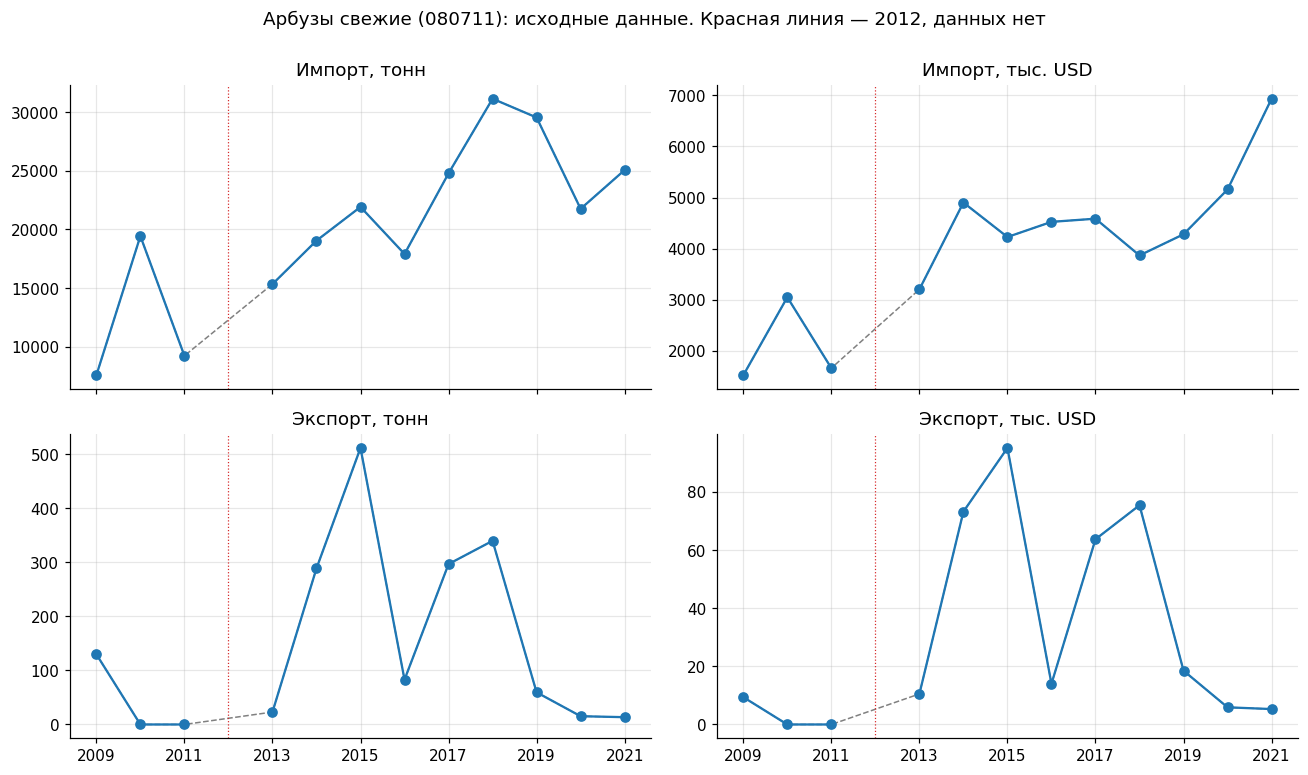

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, c in zip(axes.ravel(), COLS):
    ax.plot(data.index, data[c], '--', color='gray', lw=1)       # серый пунктир — перемычка через 2012
    ax.plot(raw.index, raw[c], 'o-', color='C0')
    ax.axvline(2012, color='C3', lw=.8, ls=':')
    ax.set_title(LABELS[c])
    ax.set_xticks(range(2009, 2022, 2))
fig.suptitle('Арбузы свежие (080711): исходные данные. Красная линия — 2012, данных нет', y=1.0)
fig.tight_layout()
plt.show()

**Что видно на графиках**

- Импорт по весу вырос примерно втрое: с 7,6 тыс. т в 2009 до 25,1 тыс. т в 2021, максимум в 2018 (31,1 тыс. т). Провалы — 2011 (9,3 тыс. т против 19,4 тыс. т годом ранее) и 2020 (21,8 тыс. т, −26%).
- По стоимости импорт ведёт себя иначе: 2021 — рекорд (6,9 млн USD), хотя по тоннам он ниже 2018. Причина в цене: средняя цена импорта в 2018 была около 124 USD/т, в 2021 — около 277 USD/т.
- Экспорт минимален по сравнению с импортом: от 0 до 512 т в год (пик 2015), в 2020–2021 всего 13–15 т. В 2010–2011 экспорта не было вообще.
- Экспортный ряд очень нестабильный: 2014–2015 рост, 2016 провал, 2017–2018 снова вверх, дальше падение. Устойчивого тренда нет.

## 2. Декомпозиция рядов

Сезонность в годовых данных быть не может, поэтому раскладываем ряд на две части: тренд и цикл (отклонения от неё, включая шум). Для этого — фильтр Ходрика–Прескотта с λ = 6,25, стандартным значением для годовых данных.


Импорт, тонн         доля дисперсии, объяснённая трендом: 69%
Импорт, тыс. USD     доля дисперсии, объяснённая трендом: 76%
Экспорт, тонн        доля дисперсии, объяснённая трендом: 31%
Экспорт, тыс. USD    доля дисперсии, объяснённая трендом: 39%


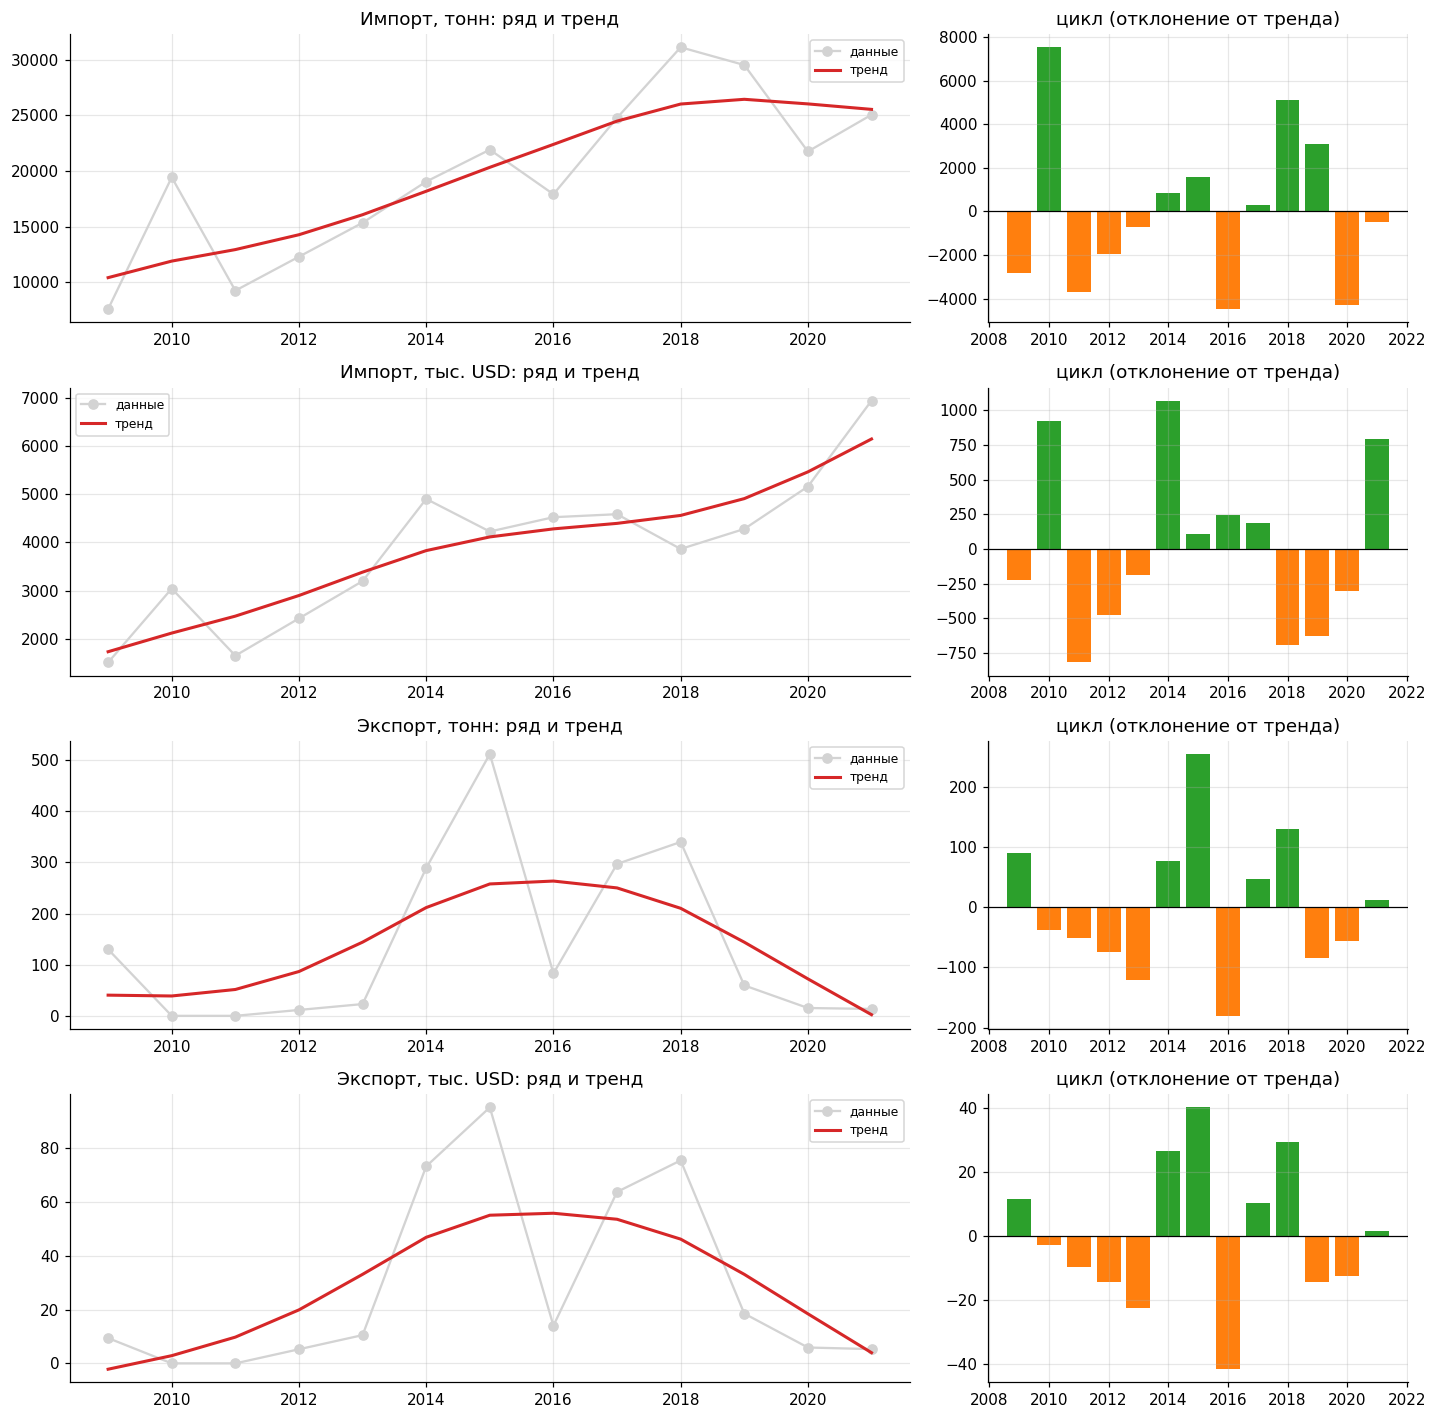

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), gridspec_kw={'width_ratios': [2, 1]})
decomp = {}

for i, c in enumerate(COLS):
    cycle, trend = hpfilter(data[c], lamb=6.25)
    decomp[c] = pd.DataFrame({'ряд': data[c], 'тренд': trend, 'цикл': cycle})

    ax = axes[i, 0]
    ax.plot(data.index, data[c], 'o-', color='lightgray', label='данные')
    ax.plot(trend, color='C3', lw=2, label='тренд')
    ax.set_title(f'{LABELS[c]}: ряд и тренд')
    ax.legend(fontsize=8)

    ax = axes[i, 1]
    ax.bar(data.index, cycle, color=np.where(cycle >= 0, 'C2', 'C1'))
    ax.axhline(0, color='k', lw=.8)
    ax.set_title('цикл (отклонение от тренда)')

    share = trend.var() / data[c].var()
    print(f'{LABELS[c]:<20} доля дисперсии, объяснённая трендом: {share:.0%}')

fig.tight_layout()
plt.show()

In [10]:
# три года с наибольшим отклонением цикла от тренда (в единицах ряда)
for c in COLS:
    cyc = decomp[c]['цикл']
    top = cyc.abs().sort_values(ascending=False).head(3).index
    print(f'{LABELS[c]:<20}', ', '.join(f'{y}: {cyc[y]:+,.0f}' for y in top))

Импорт, тонн         2010: +7,533, 2018: +5,104, 2016: -4,481
Импорт, тыс. USD     2014: +1,070, 2010: +921, 2011: -819
Экспорт, тонн        2015: +254, 2016: -181, 2018: +130
Экспорт, тыс. USD    2016: -42, 2015: +40, 2018: +29


**Интерпретация**

- *Импорт, тонны.* Тренд растёт с ~10 тыс. т в 2009 до ~26,5 тыс. т в 2019 и дальше выходит на плато. Тренд объясняет около 70% дисперсии. Самые большие отклонения цикла: всплеск 2010 (+7,5 тыс. т) и 2018 (+5,1 тыс. т), провалы 2016, 2020 и 2011 (от −3,7 до −4,5 тыс. т).
- *Импорт, стоимость.* Тренд растёт почти весь период, с 1,7 до 6,1 млн USD, и ускоряется к 2021 году. Объём при этом с 2019 года стоит на месте, значит рост стоимости идёт за счёт цены. Крупнейшие отклонения: 2014 (+1,1 млн), 2010 (+0,9), 2011 (−0,8), 2021 (+0,8).
- *Экспорт.* Тренд — «горб»: около 40 т в 2009–2011, пик ~260 т в 2015–2016 и спад почти до нуля к 2021 году. Тренд объясняет лишь 31–39% дисперсии, остальное — резкие колебания год к году (2015: +254 т, 2016: −181 т). Экспорт ближе к шуму, чем к закономерности.
- У HP-фильтра известная слабость на краях ряда: падение экспортного тренда к 2021 и отрицательный тренд стоимости экспорта в 2009 (−2 тыс. USD) — отчасти артефакт фильтра, а не реальные значения.
- 2012 год в декомпозиции — интерполяция, не наблюдение.

## 3. Прогноз на 2022–2024

### Методология

**Ряды.** Прогнозируем 4 ряда отдельно: импорт и экспорт, количество и стоимость. Работаем с логарифмом `log(1 + x)`: ряды сильно скачут и не бывают отрицательными, а в логарифмах модели ведут себя устойчивее. Нули в экспорте логарифм `log(1+x)` переносит нормально. Прогнозы возвращаем в исходный масштаб и обрезаем снизу нулём.

**Модели.**

| Группа | Модель | Комментарий |
|---|---|---|
| Базовая | Naive | значение последнего года повторяется. Любая модель должна его обыгрывать |
| Статистика | ARIMA | порядок (p, 1, q) и наличие дрейфа выбираем по AIC. Сезонность в годовых данных отсутствует, поэтому SARIMA сводится к ARIMA |
| Статистика | ETS | модель Хольта с затухающим трендом |
| ML | Ridge | линейная регрессия с регуляризацией на лагах |
| ML | Random Forest | ансамбль деревьев |
| ML | Gradient Boosting | градиентный бустинг (sklearn) |


**ML-модели.** Предсказываем изменение логарифма на следующий год по двум признакам: уровень прошлого года и прошлогоднее изменение. Прогноз на 3 года строится рекурсивно: предсказанное значение подставляется в признаки следующего шага. Без ограничений такая рекурсия на 5–8 обучающих строках легко «улетает» (при проверке прогнозы после пика 2015 года уходили в несколько раз выше исторического максимума), поэтому уровень ограничен диапазоном обучающей выборки плюс запас 0,3 в логарифмах (примерно +35% к максимуму).

**Выбор лучшей модели.** Скользящий бэктест: обучаемся на первых n годах и прогнозируем следующие 3, n = 7…10 (четыре окна, тестовые годы 2016–2021). Метрики на исходном масштабе: MAE, RMSE, sMAPE. Лучшая модель — с минимальным MAE.

**Доверительные интервалы.** У ARIMA и ETS — аналитические 95% интервалы. У остальных моделей интервал строится по ошибкам бэктеста: прогноз ± 1,96 · RMSE (в логарифмах) для соответствующего горизонта.

In [11]:
H = 3
FC_YEARS = [2022, 2023, 2024]
y_all = {c: np.log1p(data[c].values) for c in COLS}      # модели работают в логарифмах
back = lambda v: np.clip(np.expm1(v), 0, None)           # обратно в исходный масштаб

# --- каждая модель принимает ряд y и горизонт h, возвращает (прогноз, нижняя, верхняя граница)
#     границы = None, если у модели нет собственного интервала

def f_naive(y, h):
    return np.repeat(y[-1], h), None, None

def f_arima(y, h):
    # d = 1 фиксируем: AIC нельзя сравнивать между моделями с разным d,
    # а тест на единичный корень на 7–13 точках ничего не показывает
    best = None
    for p in (0, 1):
        for q in (0, 1):
            for trend in ('n', 't'):                     # 't' — дрейф
                try:
                    res = ARIMA(y, order=(p, 1, q), trend=trend).fit()
                except Exception:
                    continue
                if best is None or res.aic < best.aic:
                    best = res
    if best is None:
        return f_naive(y, h)
    fc = best.get_forecast(h)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    return np.asarray(fc.predicted_mean), ci[:, 0], ci[:, 1]

def f_ets(y, h):
    try:
        res = ETSModel(y, error='add', trend='add', damped_trend=True).fit(disp=False)
        sf = res.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.05)
        return sf['mean'].values, sf['pi_lower'].values, sf['pi_upper'].values
    except Exception:
        return f_naive(y, h)

def make_xy(y):
    # признаки: y[t-1] и y[t-1]-y[t-2]; цель: y[t]-y[t-1]
    d = np.diff(y)
    return np.column_stack([y[1:-1], d[:-1]]), d[1:]

def ml(make_model):
    def f(y, h):
        X, t = make_xy(y)
        m = make_model().fit(X, t)
        lo, hi = y.min(), y.max() + 0.3          # уровень не уходит за рамки обучающей выборки
        yy = list(y)
        for _ in range(h):
            x = [[yy[-1], yy[-1] - yy[-2]]]
            yy.append(np.clip(yy[-1] + m.predict(x)[0], lo, hi))
        return np.array(yy[-h:]), None, None
    return f

MODELS = {
    'Naive':             f_naive,
    'ARIMA':             f_arima,
    'ETS':               f_ets,
    'Ridge':             ml(lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0))),
    'Random Forest':     ml(lambda: RandomForestRegressor(n_estimators=300, max_depth=3, random_state=0)),
    'Gradient Boosting': ml(lambda: GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                                              max_depth=2, random_state=0)),
}

In [12]:
FIRST_TRAIN = 7      # минимальная длина обучающей части

def backtest(y):
    rows = []
    for n in range(FIRST_TRAIN, len(y) - H + 1):
        train, test = y[:n], y[n:n + H]
        for name, f in MODELS.items():
            pred = f(train, H)[0]
            for h in range(H):
                rows.append((name, n, h + 1, test[h], pred[h]))
    return pd.DataFrame(rows, columns=['model', 'n_train', 'h', 'actual', 'pred'])

def smape(a, p):
    return 100 * np.mean(2 * np.abs(p - a) / np.maximum(np.abs(a) + np.abs(p), 1e-9))

def score(bt):
    out = {}
    for name, g in bt.groupby('model', sort=False):
        a = np.expm1(g['actual'].values)
        p = back(g['pred'].values)
        out[name] = {'MAE': np.mean(np.abs(a - p)),
                     'RMSE': np.sqrt(np.mean((a - p) ** 2)),
                     'sMAPE, %': smape(a, p)}
    return pd.DataFrame(out).T

bts = {c: backtest(y_all[c]) for c in COLS}
scores = {c: score(bts[c]) for c in COLS}
best = {c: scores[c]['MAE'].idxmin() for c in COLS}

for c in COLS:
    print(f'\n{LABELS[c]}   (лучшая по MAE: {best[c]})')
    print(scores[c].round(1).to_string())


Импорт, тонн   (лучшая по MAE: ARIMA)
                       MAE     RMSE  sMAPE, %
Naive               6576.9   7443.4      26.5
ARIMA               4846.2   6587.9      17.7
ETS                 6576.9   7443.4      26.5
Ridge               7801.9   9123.1      29.5
Random Forest       7341.1   8376.0      30.2
Gradient Boosting  10799.7  12389.4      42.5

Импорт, тыс. USD   (лучшая по MAE: Naive)
                      MAE    RMSE  sMAPE, %
Naive               696.3  1043.0      14.8
ARIMA              2108.0  2347.5      37.5
ETS                 696.3  1043.0      14.8
Ridge               872.3  1136.1      17.9
Random Forest      1381.8  1648.1      27.2
Gradient Boosting  1237.6  1506.8      24.1

Экспорт, тонн   (лучшая по MAE: Naive)
                     MAE   RMSE  sMAPE, %
Naive              233.7  258.3     111.7
ARIMA              233.7  258.3     111.7
ETS                233.7  258.3     111.7
Ridge              277.4  314.6     119.8
Random Forest      354.9  406.5     11

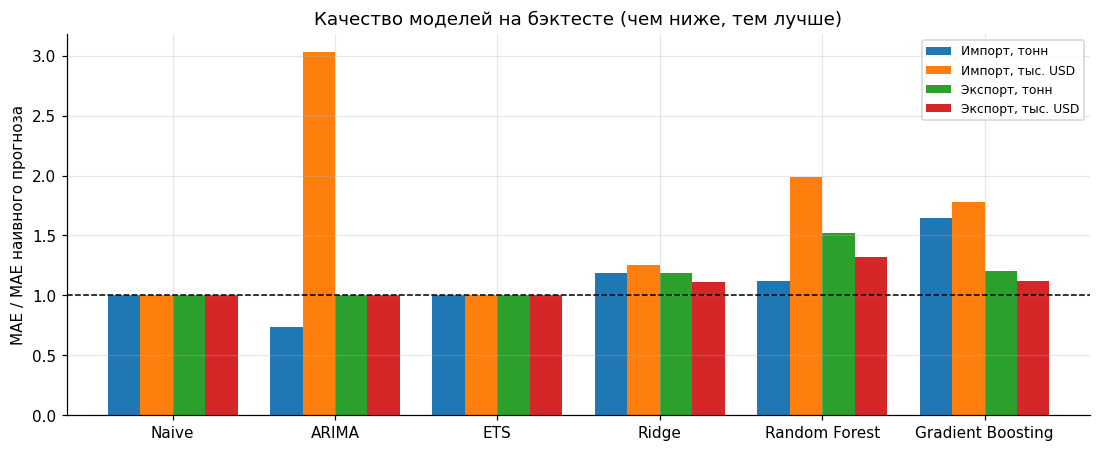

In [13]:
# MAE каждой модели относительно наивного прогноза: ниже 1 — модель лучше Naive
rel = pd.DataFrame({LABELS[c]: scores[c]['MAE'] / scores[c].loc['Naive', 'MAE'] for c in COLS})

ax = rel.plot.bar(figsize=(12, 4.5), width=.8, rot=0)
ax.axhline(1, color='k', lw=1, ls='--')
ax.set_ylabel('MAE / MAE наивного прогноза')
ax.set_title('Качество моделей на бэктесте (чем ниже, тем лучше)')
ax.legend(fontsize=8)
plt.show()

### Итоговый прогноз

Лучшую по MAE модель для каждого ряда переобучаем на всех данных 2009–2021 и строим прогноз на три года. Остальные модели нарисованы тонкими линиями для сравнения.

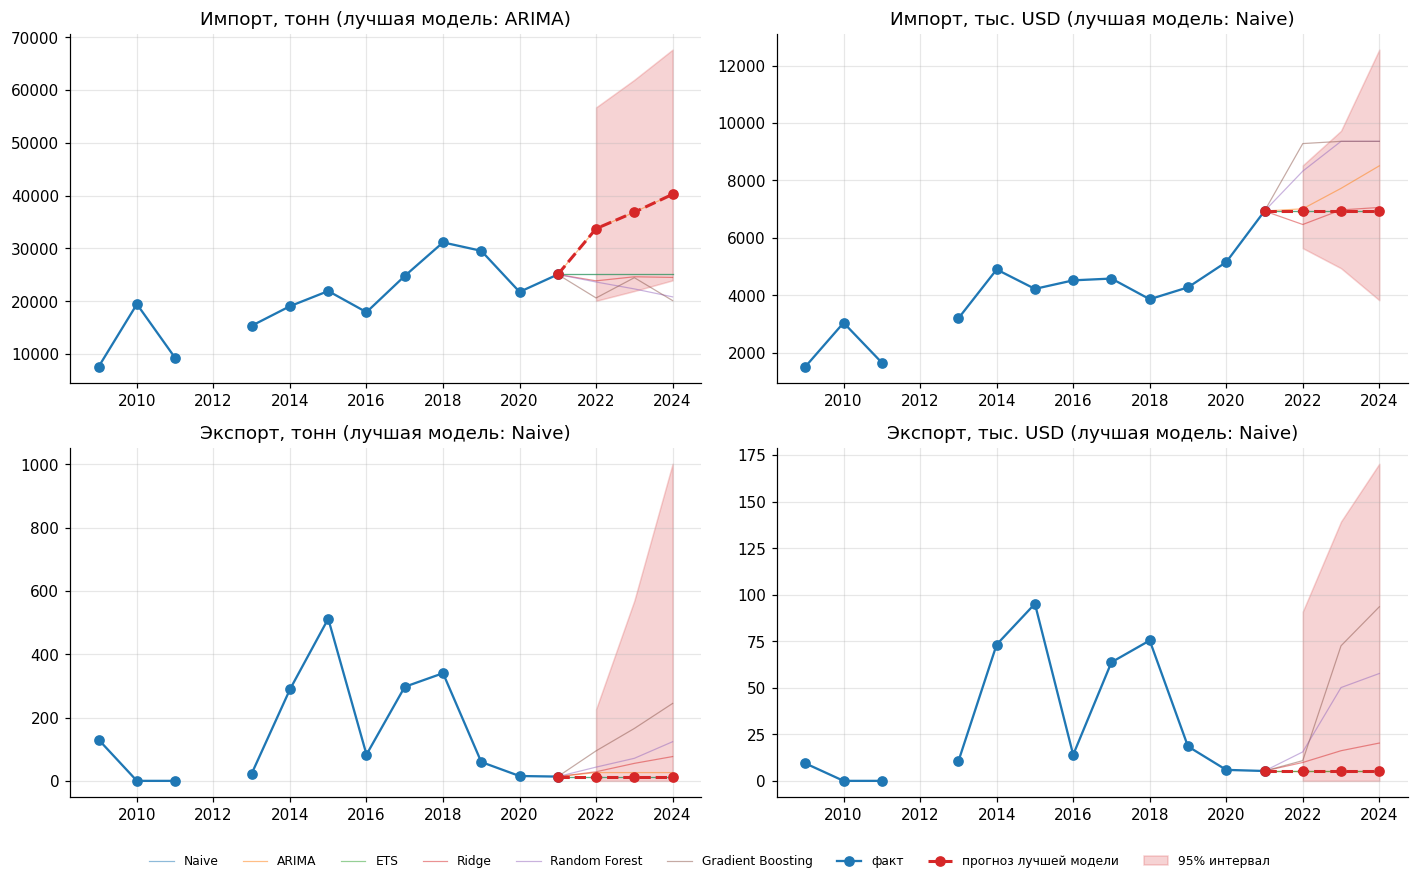

In [14]:
def sigma_by_h(bt, model):
    g = bt[bt['model'] == model]
    err = g['actual'] - g['pred']
    return np.sqrt((err ** 2).groupby(g['h']).mean()).values      # RMSE в логарифмах по горизонтам

def final_forecast(c, name):
    mean, lo, hi = MODELS[name](y_all[c], H)
    if lo is None:                       # интервал по ошибкам бэктеста
        s = sigma_by_h(bts[c], name)
        lo, hi = mean - 1.96 * s, mean + 1.96 * s
    return pd.DataFrame({'прогноз': back(mean), 'нижняя 95%': back(lo), 'верхняя 95%': back(hi)},
                        index=FC_YEARS)

fc = {c: final_forecast(c, best[c]) for c in COLS}
all_fc = {c: {n: back(f(y_all[c], H)[0]) for n, f in MODELS.items()} for c in COLS}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), COLS):
    for n, v in all_fc[c].items():
        ax.plot([2021] + FC_YEARS, [data[c].iloc[-1]] + list(v), lw=.8, alpha=.5, label=n)
    f = fc[c]
    ax.plot(raw.index, raw[c], 'o-', color='C0', label='факт')
    ax.plot([2021] + FC_YEARS, [data[c].iloc[-1]] + list(f['прогноз']), 'o--', color='C3', lw=2,
            label='прогноз лучшей модели')
    ax.fill_between(FC_YEARS, f['нижняя 95%'], f['верхняя 95%'], color='C3', alpha=.2, label='95% интервал')
    ax.set_title(f'{LABELS[c]} (лучшая модель: {best[c]})')

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=len(l), fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [15]:
table = pd.concat({LABELS[c]: fc[c].round(1) for c in COLS}, axis=1)
display(table)
table.to_csv('forecast_2022_2024.csv', encoding='utf-8-sig')

# проверка согласованности: количество и стоимость прогнозировались отдельно
chk = pd.DataFrame({
    'цена импорта, USD/т': fc['imp_val']['прогноз'] / fc['imp_qty']['прогноз'] * 1000,
    'цена экспорта, USD/т': fc['exp_val']['прогноз'] / fc['exp_qty']['прогноз'] * 1000,
}).round(0)
print('Подразумеваемая цена из прогнозов (для сравнения: импорт 2021 — 277 USD/т):')
display(chk)

Импорт, тонн                        Импорт, тыс. USD             \
          прогноз нижняя 95% верхняя 95%          прогноз нижняя 95%   
2022      33734.1    20072.0     56695.1           6936.0     5642.8   
2023      36844.2    21922.4     61922.4           6936.0     4944.4   
2024      40241.1    23943.5     67631.6           6936.0     3831.4   

                 Экспорт, тонн                        Экспорт, тыс. USD  \
     верхняя 95%       прогноз нижняя 95% верхняя 95%           прогноз   
2022      8525.4          13.5        0.0       226.3               5.3   
2023      9729.7          13.5        0.0       569.2               5.3   
2024     12555.8          13.5        0.0      1001.4               5.3   

                             
     нижняя 95% верхняя 95%  
2022        0.0        90.9  
2023        0.0       139.3  
2024        0.0       170.3

Подразумеваемая цена из прогнозов (для сравнения: импорт 2021 — 277 USD/т):


,"цена импорта, USD/т","цена экспорта, USD/т"
2022,206.0,393.0
2023,188.0,393.0
2024,172.0,393.0


In [16]:
lines = []
for c in COLS:
    s, f = scores[c], fc[c]
    b = best[c]
    line = (f'- **{LABELS[c]}.** Лучшая модель — {b} (MAE {s.loc[b, "MAE"]:,.1f}, '
            f'наивный прогноз: {s.loc["Naive", "MAE"]:,.1f}). '
            f'Прогноз на 2024: {f["прогноз"].iloc[-1]:,.1f} '
            f'(95% интервал {f["нижняя 95%"].iloc[-1]:,.1f}–{f["верхняя 95%"].iloc[-1]:,.1f}).')
    if b == 'Naive':
        line += ' Ни одна модель не обыграла наивный прогноз.'
    lines.append(line)
display(Markdown('\n'.join(lines)))

- **Импорт, тонн.** Лучшая модель — ARIMA (MAE 4,846.2, наивный прогноз: 6,576.9). Прогноз на 2024: 40,241.1 (95% интервал 23,943.5–67,631.6).
- **Импорт, тыс. USD.** Лучшая модель — Naive (MAE 696.3, наивный прогноз: 696.3). Прогноз на 2024: 6,936.0 (95% интервал 3,831.4–12,555.8). Ни одна модель не обыграла наивный прогноз.
- **Экспорт, тонн.** Лучшая модель — Naive (MAE 233.7, наивный прогноз: 233.7). Прогноз на 2024: 13.5 (95% интервал 0.0–1,001.4). Ни одна модель не обыграла наивный прогноз.
- **Экспорт, тыс. USD.** Лучшая модель — Naive (MAE 46.6, наивный прогноз: 46.6). Прогноз на 2024: 5.3 (95% интервал 0.0–170.3). Ни одна модель не обыграла наивный прогноз.

### Как читать результат

- Бэктест здесь — четыре перекрывающихся окна на 7–10 годах обучения. Разница в качестве между близкими моделями находится в пределах шума, и выбор «лучшей» надёжен только там, где отрыв от остальных большой.
- Интервалы для экспорта заметно шире относительно уровня, чем для импорта, а нижняя граница упирается в ноль. Это отражение того, что ряд почти случайный.
- ML-модели обучаются на 5–8 строках, оценки таких моделей неустойчивы, и слабый результат на бэктесте здесь ожидаем. ML-подход раскрылся бы на больших выборках (помесячные данные, группа товаров вместо одной позиции).
- Количество и стоимость прогнозировались независимо, а в таблице цены выше видно, насколько согласованы эти прогнозы между собой.

## 4. Курс BYN/USD и стоимость торговли

Курс берём из API Национального банка РБ (официальный курс USD, `Cur_ID = 145`) за 2008–2024 гг. и усредняем по годам. До деноминации (июль 2016) курс в API указан в старых рублях, поэтому значения больше 100 делим на 10 000: так весь период приводится к современным белорусским рублям.

Что считаем: корреляцию курса со стоимостью торговли (и с количеством для сравнения) по двум схемам.
1. **По уровням** (Пирсон и Спирмен).
2. **По годовым изменениям** логарифмов. Это очищает общий тренд, но оставляет лишь 10 пар наблюдений (2012-й пропущен, и из-за него выпадают два изменения).

In [17]:
FX_FILE = 'usd_byn_daily.csv'

def fetch_usd_byn(y0=2008, y1=2024):
    rows = []
    for y in range(y0, y1 + 1):
        # API отдаёт не больше года за запрос, берём по полугодию
        for a, b in [(f'{y}-01-01', f'{y}-06-30'), (f'{y}-07-01', f'{y}-12-31')]:
            r = requests.get('https://api.nbrb.by/exrates/rates/dynamics/145',
                             params={'startdate': a, 'enddate': b}, timeout=30)
            r.raise_for_status()
            rows += r.json()
    df = pd.DataFrame(rows)
    df['date'] = pd.to_datetime(df['Date'])
    df['rate'] = df['Cur_OfficialRate'].astype(float)
    df.loc[df['rate'] > 100, 'rate'] /= 10000            # старые рубли -> новые
    return df[['date', 'rate']].sort_values('date')

if os.path.exists(FX_FILE):
    fx_daily = pd.read_csv(FX_FILE, parse_dates=['date'])
else:
    fx_daily = fetch_usd_byn()
    fx_daily.to_csv(FX_FILE, index=False)

assert fx_daily['rate'].between(0.1, 5).all(), 'курс вне ожидаемого диапазона — проверьте деноминацию'

fx = fx_daily.groupby(fx_daily['date'].dt.year)['rate'].mean()
fx.index.name = 'год'
print(f'{len(fx_daily)} дневных значений, годы {fx.index.min()}–{fx.index.max()}')
print(fx.round(3).to_string())

4938 дневных значений, годы 2008–2021
год
2008    0.214
2009    0.279
2010    0.298
2011    0.500
2012    0.834
2013    0.888
2014    1.023
2015    1.591
2016    1.988
2017    1.932
2018    2.038
2019    2.091
2020    2.439
2021    2.572


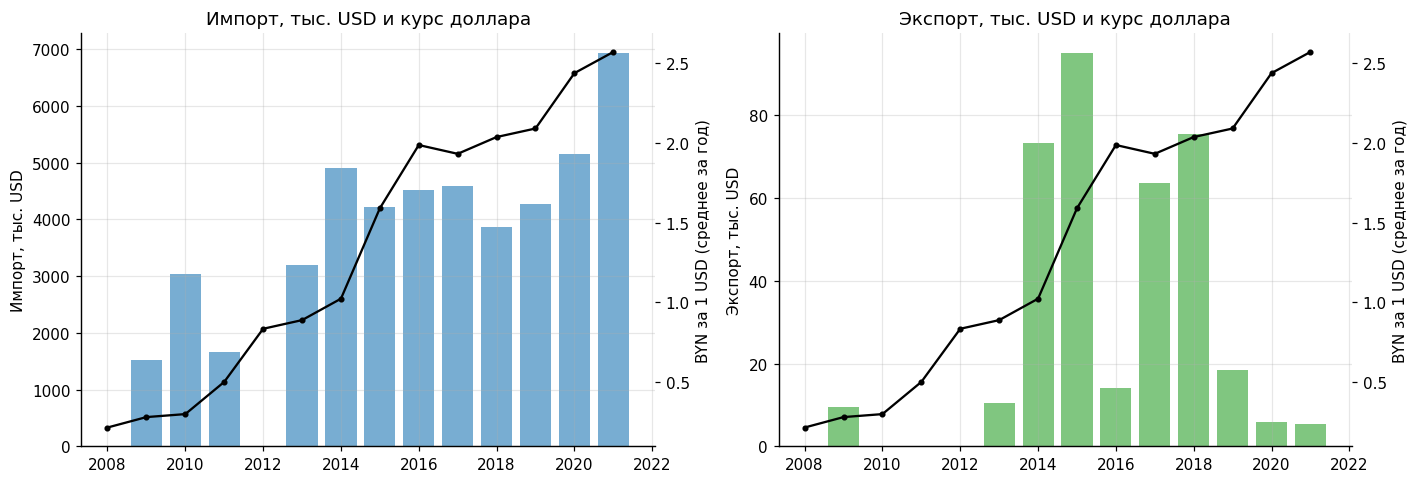

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c, color in zip(axes, ['imp_val', 'exp_val'], ['C0', 'C2']):
    ax.bar(raw.index, raw[c], color=color, alpha=.6)
    ax.set_ylabel(LABELS[c])
    ax2 = ax.twinx()
    ax2.plot(fx.index, fx.values, 'k-o', ms=3)
    ax2.set_ylabel('BYN за 1 USD (среднее за год)')
    ax2.grid(False)
    ax.set_title(f'{LABELS[c]} и курс доллара')
fig.tight_layout()
plt.show()

In [19]:
rows = []
for c in COLS:
    lv = pd.DataFrame({'y': raw[c], 'fx': fx}).dropna()               # только реальные годы
    r_p, p_p = stats.pearsonr(lv['fx'], lv['y'])
    r_s, p_s = stats.spearmanr(lv['fx'], lv['y'])

    ch = pd.DataFrame({'y': np.log1p(raw[c]).diff(), 'fx': np.log(fx).diff()}).dropna()
    r_d, p_d = stats.pearsonr(ch['fx'], ch['y'])

    rows.append({'ряд': LABELS[c], 'n (уровни)': len(lv),
                 'Пирсон': r_p, 'p (Пирсон)': p_p, 'Спирмен': r_s, 'p (Спирмен)': p_s,
                 'n (изм.)': len(ch), 'Пирсон, изм.': r_d, 'p (изм.)': p_d})

corr = pd.DataFrame(rows).set_index('ряд')
display(corr.round(3))

,n (уровни),Пирсон,p (Пирсон),Спирмен,p (Спирмен),n (изм.),"Пирсон, изм.",p (изм.)
ряд,,,,,,,,
"Импорт, тонн",12,0.759,0.004,0.748,0.005,10,-0.589,0.073
"Импорт, тыс. USD",12,0.832,0.001,0.804,0.002,10,-0.623,0.054
"Экспорт, тонн",12,0.131,0.685,0.074,0.820,10,0.147,0.685
"Экспорт, тыс. USD",12,0.200,0.534,0.207,0.519,10,0.028,0.938


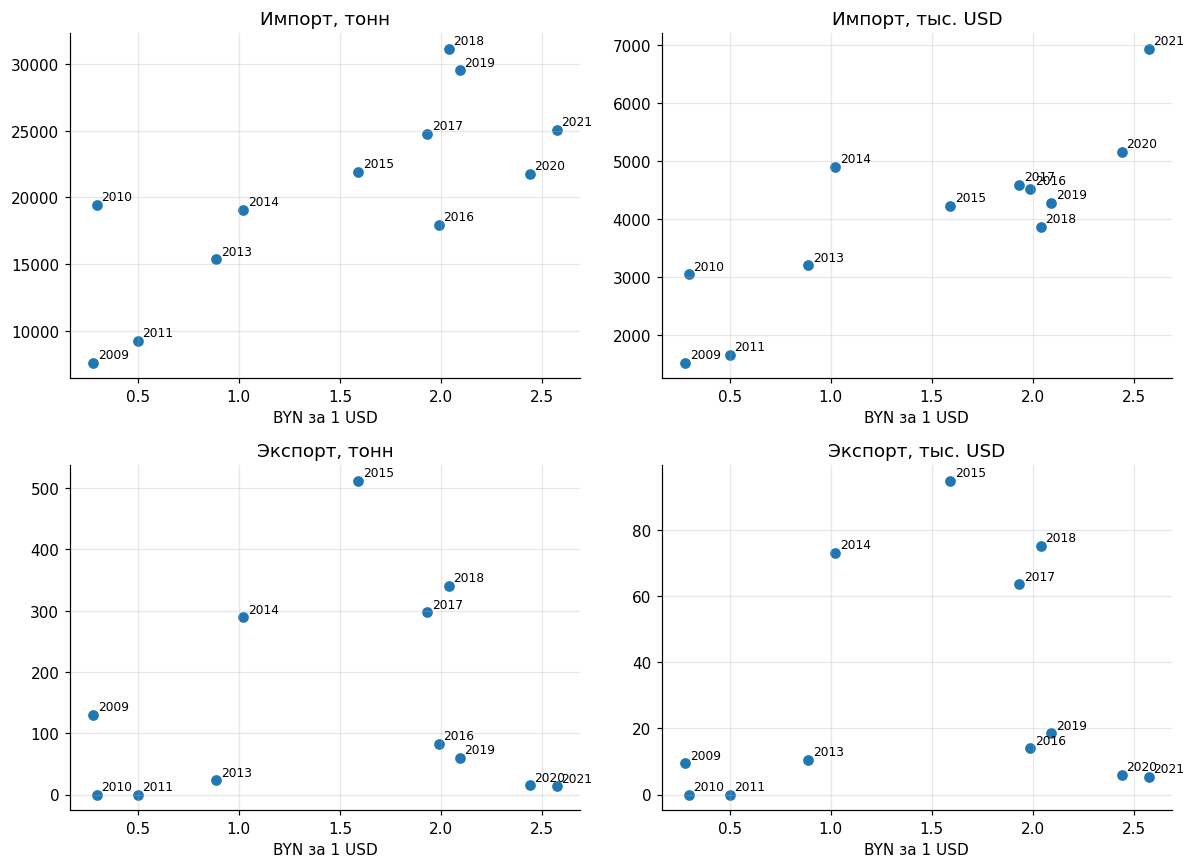

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, c in zip(axes.ravel(), COLS):
    d = pd.DataFrame({'y': raw[c], 'fx': fx}).dropna()
    ax.scatter(d['fx'], d['y'], color='C0')
    for yr, r in d.iterrows():
        ax.annotate(str(yr), (r['fx'], r['y']), fontsize=8, xytext=(3, 3), textcoords='offset points')
    ax.set_xlabel('BYN за 1 USD')
    ax.set_title(LABELS[c])
fig.tight_layout()
plt.show()

In [21]:
lines = []
for name, r in corr.iterrows():
    sig = lambda p: 'значима' if p < 0.05 else 'не значима'
    lines.append(f'- **{name}.** По уровням: Пирсон {r["Пирсон"]:+.2f} ({sig(r["p (Пирсон)"])}), '
                 f'Спирмен {r["Спирмен"]:+.2f} ({sig(r["p (Спирмен)"])}). '
                 f'По изменениям: {r["Пирсон, изм."]:+.2f} ({sig(r["p (изм.)"])}, n = {int(r["n (изм.)"])}).')
display(Markdown('\n'.join(lines)))

- **Импорт, тонн.** По уровням: Пирсон +0.76 (значима), Спирмен +0.75 (значима). По изменениям: -0.59 (не значима, n = 10).
- **Импорт, тыс. USD.** По уровням: Пирсон +0.83 (значима), Спирмен +0.80 (значима). По изменениям: -0.62 (не значима, n = 10).
- **Экспорт, тонн.** По уровням: Пирсон +0.13 (не значима), Спирмен +0.07 (не значима). По изменениям: +0.15 (не значима, n = 10).
- **Экспорт, тыс. USD.** По уровням: Пирсон +0.20 (не значима), Спирмен +0.21 (не значима). По изменениям: +0.03 (не значима, n = 10).

## 5. Выводы

# Данные и их ограничения

- Ряд короткий: 13 годовых точек, из них 2012 год отсутствует и заполнен линейной интерполяцией. Все метрики качества считались только по реальным наблюдениям, но интерполяция всё равно влияет на HP-фильтр и обучение моделей.
- Единицы приведены к тоннам (экспорт 2019–2021 в исходных файлах в кг), текстовые числа («24 780») переведены в числовой формат, «-» принят за ноль.
- Импорт и экспорт несопоставимы по масштабу: в 2021 году импорт 25 061 т против 13,5 т экспорта. Для практических решений значим в первую очередь импорт. Экспорт в этой товарной группе фактически эпизодический.
- Сезонность выделить нельзя: данные годовые. Требование разложения на тренд, сезонность и остатки выполнено как «тренд + цикл (остаток)». Сезонная компонента не оценивалась, для её оценки нужны помесячные данные.

### Декомпозиция рядов

**Метод.** Фильтр Ходрика–Прескотта, λ = 6,25 (стандарт для годовых данных). Ряд делится на гладкий тренд и циклическую компоненту, в которую входит и шум.

**Результаты.**

| Ряд | Доля дисперсии, объяснённая трендом | Что показывает тренд |
|---|---|---|
| Импорт, тонн | 69% | рост с ~10 до ~26,5 тыс. т к 2019 году, затем плато |
| Импорт, тыс. USD | 76% | рост с ~1,7 до ~6,1 млн USD, ускорение к 2021 |
| Экспорт, тонн | 31% | «горб»: ~40 т в 2009–2011, ~260 т в 2015–2016, около нуля к 2021 |
| Экспорт, тыс. USD | 39% | та же форма, что и по тоннам |

**Интерпретация.**

1. Импорт имеет выраженный долгосрочный рост. Физический объём за 2009–2021 вырос в 3,3 раза (7,6 → 25,1 тыс. т), стоимость в 4,6 раза (1,5 → 6,9 млн USD).
2. С 2019 года объёмный тренд стоит на месте, а стоимостной продолжает расти. Следовательно, рост стоимости последних лет обеспечен ценой, а не объёмом: средняя цена импорта выросла со 124 USD/т (2018) до 277 USD/т (2021).
3. Наибольшие отклонения от тренда по импорту в тоннах: 2010 (+7,5 тыс. т), 2018 (+5,1), 2016 (−4,5). По стоимости: 2014 (+1,07 млн USD), 2010 (+0,92), 2011 (−0,82). Эти годы нельзя считать случайным шумом без проверки причин (урожай, логистика, курс), но в рамках данных объяснить их нельзя.
4. По экспорту тренд объясняет менее 40% дисперсии. Остальное — резкие скачки год к году (2015: +254 т к тренду, 2016: −181 т). Это не тренд с отклонениями, а шумоподобный ряд.
5. Ограничение метода: HP-фильтр ненадёжен на краях ряда. Спад экспортного тренда к 2021 и отрицательный тренд стоимости экспорта в 2009 (около −2 тыс. USD) частично создаются самим фильтром. Значение 2012 года в декомпозиции — интерполяция.
**Вывод по блоку.** Импорт — ряд с устойчивой восходящей компонентой, экспорт — ряд без устойчивой закономерности.

### Прогноз на 2022–2024

**Методология.** Прогноз строился для каждого из 4 рядов отдельно, в логарифмах `log(1+x)`, с возвратом в исходный масштаб и ограничением снизу нулём. Сравнивались шесть моделей:

- базовая: Naive (последнее значение повторяется);
- статистические: ARIMA (порядок (p,1,q) и дрейф подбираются по AIC), ETS (Хольт с затухающим трендом);
- машинное обучение: Ridge, Random Forest, Gradient Boosting на двух признаках (уровень прошлого года и прошлогоднее изменение), прогноз на 3 года рекурсивный, уровень ограничен диапазоном обучающей выборки плюс 0,3 в логарифмах.
Качество оценивалось скользящим бэктестом (обучение на первых 7–10 годах, прогноз на следующие 3), метрики MAE, RMSE, sMAPE в исходном масштабе. Лучшая модель выбиралась по минимальному MAE.

!!! Вместо SARIMA использована ARIMA (при годовых данных сезонных параметров нет). Prophet, XGBoost и LSTM не применялись: на 13 точках (5–8 обучающих строк после лагов) нейросеть и Prophet с годовой сезонностью не имеют смысла, а вместо XGBoost/LightGBM взят градиентный бустинг из sklearn. Это ограничение данных, а не случайный выбор.

**Результаты бэктеста (MAE, меньше — лучше).**

| Ряд | Naive | ARIMA | ETS | Ridge | RF | GB | Лучшая |
|---|---|---|---|---|---|---|---|
| Импорт, тонн | 6 577 | **4 846** | 6 577 | 7 802 | 7 341 | 10 800 | ARIMA |
| Импорт, тыс. USD | **696** | 2 108 | 696 | 872 | 1 382 | 1 238 | Naive |
| Экспорт, тонн | **233,7** | 233,7 | 233,7 | 277,4 | 354,9 | 280,5 | Naive |
| Экспорт, тыс. USD | **46,6** | 46,6 | 46,6 | 51,9 | 61,5 | 52,3 | Naive |

Таким образом

1. Статистический подход оказался лучше машинного обучения по всем четырём рядам. Ни Ridge, ни Random Forest, ни Gradient Boosting не дали MAE ниже Naive. Причина — объём выборки: модель с двумя признаками на 5–8 строках не может отличить закономерность от шума.
2. Единственная модель, обыгравшая Naive, — ARIMA для импорта в тоннах: MAE ниже на 26% (4 846 против 6 577), RMSE ниже на 11%, sMAPE 17,7% против 26,5%. Отрыв умеренный, он получен на четырёх перекрывающихся окнах и надёжным доказательством превосходства не является.
3. Для остальных трёх рядов ни одна модель не лучше повторения последнего значения. ETS совпадает с Naive: демпфированный тренд на этих данных «схлопывается» в ноль. ARIMA для экспорта совпадает с Naive по той же причине, а для стоимости импорта работает заметно хуже (MAE 2 108 против 696): дрейф, подобранный по короткой истории, на тестовых окнах давал ошибку.
4. Для экспорта sMAPE выше 100% у всех моделей. Это означает, что ошибка сопоставима с самим значением: ряд не прогнозируется имеющимися методами.
**Итоговый прогноз (лучшая модель по MAE, 95% интервал).**

| Показатель | Модель | 2022 | 2023 | 2024 | Интервал 95%, 2024 |
|---|---|---|---|---|---|
| Импорт, тонн | ARIMA | 33 734 | 36 844 | 40 241 | 23 944 – 67 632 |
| Импорт, тыс. USD | Naive | 6 936 | 6 936 | 6 936 | 3 831 – 12 556 |
| Экспорт, тонн | Naive | 13,5 | 13,5 | 13,5 | 0 – 1 001 |
| Экспорт, тыс. USD | Naive | 5,3 | 5,3 | 5,3 | 0 – 170 |

Интервалы для Naive-прогнозов построены по ошибкам бэктеста (прогноз ± 1,96·RMSE в логарифмах), поэтому они очень широкие, а у экспорта нижняя граница равна нулю.

ПРОГНОЗ!!! Значения по всем годам — в `forecast_2022_2024.csv`.


### Курс BYN/USD и стоимость торговли

**Методология.** Официальный курс USD НБ РБ (API, `Cur_ID = 145`), усреднён по годам. Значения до деноминации (июль 2016) пересчитаны делением на 10 000. Корреляции считались по уровням (Пирсон, Спирмен) и по годовым изменениям логарифмов. Все цифры ниже получены на периоде 2009–2021 (в загруженном курсе 2008–2021, 2022–2024 в данных нет), для уровней n = 12 (2012 исключён), для изменений n = 10.

**Результаты.**

| Ряд | Уровни: Пирсон | Спирмен | Изменения: Пирсон (p) |
|---|---|---|---|
| Импорт, тонн | +0,76 (p=0,004) | +0,75 (p=0,005) | −0,59 (p=0,073) |
| Импорт, тыс. USD | +0,83 (p=0,001) | +0,80 (p=0,002) | −0,62 (p=0,054) |
| Экспорт, тонн | +0,13 (p=0,685) | +0,07 (p=0,820) | +0,15 (p=0,685) |
| Экспорт, тыс. USD | +0,20 (p=0,534) | +0,21 (p=0,519) | +0,03 (p=0,938) |

**Интерпретация.**

1. По уровням импорт сильно и значимо коррелирует с курсом (0,76–0,83). Но это корреляция двух растущих рядов: курс вырос с 0,21 до 2,57 BYN за USD (в ~12 раз), и импорт тоже вырос. Такая связь — стандартный случай ложной корреляции нестационарных рядов, и считать её причинной нельзя.
2. После перехода к годовым изменениям (что убирает общий тренд) знак меняется: −0,59 для тонн и −0,62 для стоимости. То есть в годы, когда рубль заметно слабел, импорт в долларах имел тенденцию падать. Экономически это объяснимо (импорт дорожает для внутренних покупателей), но статистически слабо: p = 0,054 и 0,073, на уровне 5% связь не значима, а n = 10.
3. По экспорту связи нет ни по уровням, ни по изменениям (|r| ≤ 0,21, p > 0,5). Для ряда с объёмами 0–512 т другого результата ожидать не приходилось.
4. Стоимость торговли в USD не должна зависеть от курса напрямую. Возможная связь идёт через спрос и цены в BYN, и в анализе она не разделена с другими факторами (урожай в странах-поставщиках, курс российского рубля, цены на логистику).

Устойчивой статистически значимой связи между курсом BYN/USD и стоимостью импорта или экспорта арбузов данные не подтверждают. Для импорта есть слабый, граничный по значимости отрицательный сигнал в годовых изменениях. Для экспорта связи нет. Прямой запрос задания — период 2008–2024 — в расчёте покрыт только до 2021 года, потому что торговые данные заканчиваются в 2021-м.

### Общий итог

1. Импорт арбузов в Беларусь за 2009–2021 годы устойчиво вырос, с плато по объёму после 2019 года и дальнейшим ростом по стоимости за счёт цены. Экспорт мал и нерегулярен.
2. Из шести моделей только ARIMA для импорта в тоннах обыграла Naive; ML-модели на 13 годовых наблюдениях хуже статистических и базовой.
3. Надёжны прогнозы направления для импорта в тоннах (рост, но с завышенным первым годом). Остальные три показателя прогнозируются на уровне последнего значения с интервалами, которые охватывают от нуля до многократного превышения.
4. Корреляция с курсом по уровням завышена общим трендом; после его удаления связь отрицательная и слабая для импорта, отсутствует для экспорта.
